# Chapter 18: Case study: a quadrotor with a cable-suspended load

One robot through the whole recipe, in one flight: plan the load, recover the vehicle, track, linearize,
adapt to an unknown load mass and a gust, keep the cable taut and inside a cone, estimate the cable, and fly.

Sections follow the chapter:

1. The mission
2. Dynamics you can trust
3. Planning the load, not the vehicle
4. Tracking a moving load
5. Linearizing on the whole manifold
6. What you did not pick up
7. Keeping the cable honest
8. Estimating the cable
9. The whole flight
10. Starting points for the exercises

Notation follows the book: $\dot R = R\,\Omega^\wedge$, $\dot q = \omega\times q$, the cable direction $q$ points from
the quadrotor to the load, $x_Q = x_L - l\,q$, gravity acts along $-e_3$, and an estimate carries a hat
(`qhat`, `omegahat`). Only NumPy, SciPy and Matplotlib are needed. The functions are copied from the book's
robot model library (`case_studies/robots`) and from the scripts that verify Chapters 8, 10, 14 and 18, so
that the notebook runs on its own. Each flight takes a few seconds.

In [1]:
import math
import time
from dataclasses import dataclass, field, replace

import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import expm, solve_continuous_are

E1, E2, E3 = np.eye(3)
I3 = np.eye(3)
G = 9.81
INDIGO, TERRACOTTA, TEAL, MUTED, INK = "#1b1f8a", "#c85a32", "#2a6f73", "#646873", "#1a1a1a"


def cross(a, b):
    """a x b for two vectors of R^3 (np.cross is slow on single vectors)."""
    return np.array([a[1] * b[2] - a[2] * b[1], a[2] * b[0] - a[0] * b[2], a[0] * b[1] - a[1] * b[0]])


# ---- copied from case_studies/robots/core.py: operators and the errors of Chapter 3
def hat(x):
    """hat(x) y = x cross y."""
    return np.array([[0.0, -x[2], x[1]], [x[2], 0.0, -x[0]], [-x[1], x[0], 0.0]])


def vee(A):
    """Inverse of hat."""
    return np.array([A[2, 1], A[0, 2], A[1, 0]])


def expm_so3(x):
    """exp(hat(x)), Rodrigues' formula (prop2-rodrigues)."""
    angle = np.linalg.norm(x)
    if angle < 1e-12:
        return np.eye(3) + hat(x)
    K = hat(x / angle)
    return np.eye(3) + np.sin(angle) * K + (1.0 - np.cos(angle)) * K @ K


def log_so3(R):
    """Rotation vector of R: log(R) with the vee map applied."""
    angle = np.arccos(np.clip((np.trace(R) - 1.0) / 2.0, -1.0, 1.0))
    if angle < 1e-9:
        return vee(R - R.T) / 2.0
    if np.pi - angle < 1e-6:
        S = (R + np.eye(3)) / 2.0
        a = np.sqrt(np.clip(np.diag(S), 0.0, None))
        k = int(np.argmax(a))
        return angle * S[:, k] / a[k]
    return angle * vee(R - R.T) / (2.0 * np.sin(angle))


def unit(x):
    x = np.asarray(x, float)
    return x / np.linalg.norm(x)


def tangent(q, x):
    """(I - q q^T) x: the part of x in the tangent plane at q (eq4-sph-proj)."""
    return x - (x @ q) * q


def e_R(R, Rd):
    return 0.5 * vee(Rd.T @ R - R.T @ Rd)


def e_Omega(R, Omega, Rd, Omegad):
    return Omega - R.T @ Rd @ Omegad


def e_q(q, qd):
    return np.cross(qd, q)


def e_omega(q, omega, omegad):
    return omega - tangent(q, omegad)


def attitude_tracking_torque(R, Omega, Rd, Omegad, Omegad_dot, J, k_R, k_Omega):
    """The attitude tracking law, eq6-law:

    tau = -k_R e_R - k_Omega e_Omega
          + Omega x J Omega - J (Omega x R^T Rd Omegad - R^T Rd Omegad_dot).
    """
    return (-k_R * e_R(R, Rd) - k_Omega * e_Omega(R, Omega, Rd, Omegad)
            + np.cross(Omega, J @ Omega)
            - J @ (np.cross(Omega, R.T @ Rd @ Omegad) - R.T @ Rd @ Omegad_dot))


# ---- copied from case_studies/robots/quadrotor.py: eq6-Rd
def desired_attitude(F, heading):
    """eq6-Rd: third axis along F, first axis as close to the heading direction as
    that allows. heading is the unit vector R_z(psi_d) e1, with psi_d the desired
    heading (not the Euler yaw, unless the roll or the pitch is zero)."""
    b3 = unit(F)
    b2 = unit(np.cross(b3, heading))
    return np.column_stack([np.cross(b2, b3), b2, b3])

## 1. The mission

**Change the mission here.** The waypoints of the load, the travel time, the mass that was really picked up,
the cone and the tension floor are the numbers the exercises ask you to vary. Everything below reads them.

In [2]:
@dataclass
class Params:
    """The library defaults (the worked example of sec4-products)."""
    m_Q: float = 1.5        # quadrotor mass, kg
    m_L: float = 0.3        # load mass, kg
    l: float = 1.0          # cable length, m
    J: np.ndarray = field(default_factory=lambda: np.array(
        [[0.02, 0.0005, 0.0], [0.0005, 0.025, 0.001], [0.0, 0.001, 0.04]]))   # kg m^2
    g: float = G


P0 = Params()                               # what the controller believes: m_L = 0.3 kg
M_L_TRUE = 0.45                             # what was picked up            <-- change me
P_TRUE = replace(P0, m_L=M_L_TRUE)
H = 2e-3                                    # time step and sampling period, s
F_MAX = 2.0 * (P0.m_Q + P0.m_L) * P0.g      # thrust limit: twice the believed hover thrust
TAU_MAX = 1.0                               # torque limit per axis, N·m
PSI0 = np.zeros(3)                          # heading psi_d = 0 and its derivatives
WAYPOINTS = np.array([[0.0, 0.0, 0.3], [1.3, -0.45, 1.1], [2.5, 0.9, 1.3], [3.7, 2.25, 1.05],
                      [5.0, 1.8, 0.5]])
TIME_FRACTIONS = np.array([0.0, 0.314, 0.5, 0.686, 1.0])   # when the load passes each waypoint
T_START, T_TRAVEL, T_END = 0.5, 6.0, 9.0    # wait, travel, end of the run   <-- change me
GUST = (2.5, 5.0)                           # the crosswind blows between these times
WALL = dict(x=2.5, height=1.0, y=(-0.9, 2.7), thick=0.08)
CONE_DEG = 25.0                             # half-angle of the cable cone about -e3
Q_C = -E3
T_MIN = 0.5                                 # the tension the filter keeps, N
ALPHA = (12.0, 12.0)                        # rates alpha_1, alpha_2 of the cone condition, 1/s
T_HURRY = 5.0                               # the same course, asked for in less time
DROP = np.array([[0.0, 0.0, 2.0], [0.0, 0.0, 0.5]])   # a descent that all but slackens the cable
T_DROP = 1.1


@dataclass
class Gains:
    """Gains of the load cascade for the library's default vehicle (m_Q = 1.5 kg).
    Position loop at 2 rad/s and cable loop at 5 rad/s, as in sec6-cascade. The
    attitude loop is at 20 rad/s about the two light axes."""
    k_x: float = 4.0 * (P0.m_Q + P0.m_L)
    k_v: float = 2.8 * (P0.m_Q + P0.m_L)
    k_q: float = 25.0
    k_omega: float = 7.0
    k_R: float = 8.0
    k_Omega: float = 1.2

## 2. Dynamics you can trust

The equations of motion are those of the library (`eq4-load`), with a force $F_e$ on the quadrotor added to the
thrust vector. The step is the library's: fourth-order stages on one increment per factor, and the exponential
update at the end, so $\|q\| = 1$ and $R^\top R = I$ hold to rounding error.

In [3]:
@dataclass
class State:
    x_L: np.ndarray = field(default_factory=lambda: np.zeros(3))    # load position
    v_L: np.ndarray = field(default_factory=lambda: np.zeros(3))    # load velocity
    q: np.ndarray = field(default_factory=lambda: -E3.copy())       # cable direction
    omega: np.ndarray = field(default_factory=lambda: np.zeros(3))  # of the cable, world frame
    R: np.ndarray = field(default_factory=lambda: np.eye(3))        # quadrotor attitude
    Omega: np.ndarray = field(default_factory=lambda: np.zeros(3))  # body angular velocity


class Robot:
    """Copied from case_studies/robots (quadrotor_load.py and the step of core.py, written
    out for this robot). The input is u = (f, tau) or u = (f, tau, F_e)."""
    State = State

    def __init__(self, params=None):
        self.params = params or Params()

    def hover_input(self, params=None):
        p = params or self.params
        return (p.m_Q + p.m_L) * p.g, np.zeros(3)

    def dynamics(self, state, u, params=None):
        p = params or self.params
        f, tau = u[0], u[1]
        d = u[2] if len(u) > 2 else np.zeros(3)
        q, omega = state.q, state.omega
        thrust = f * state.R @ E3 + d
        q_dot = cross(omega, q)
        v_L_dot = (q @ thrust - p.m_Q * p.l * q_dot @ q_dot) * q / (p.m_Q + p.m_L) - p.g * E3
        omega_dot = -cross(q, thrust) / (p.m_Q * p.l)
        Omega_dot = np.linalg.solve(p.J, tau - cross(state.Omega, p.J @ state.Omega))
        return v_L_dot, omega_dot, Omega_dot

    def tension(self, state, u, params=None):
        """eq4-load-tension. Positive when the cable pulls."""
        p = params or self.params
        d = u[2] if len(u) > 2 else np.zeros(3)
        q_dot = cross(state.omega, state.q)
        return p.m_L / (p.m_Q + p.m_L) * (p.m_Q * p.l * q_dot @ q_dot
                                          - state.q @ (u[0] * state.R @ E3 + d))

    def on_manifold(self, state):
        return float(max(abs(np.linalg.norm(state.q) - 1.0), abs(state.q @ state.omega),
                         np.abs(state.R.T @ state.R - I3).max()))

    def step(self, state, u, h, params=None):
        """One fourth-order step with the input held; stays on the manifold (eq4-lie-euler)."""
        p = params or self.params

        def moved(inc, vel):
            return State(x_L=state.x_L + inc[0], v_L=vel[0], q=expm_so3(inc[1]) @ state.q, omega=vel[1],
                         R=state.R @ expm_so3(inc[2]), Omega=vel[2])

        def slope(inc, vel):
            acc = self.dynamics(moved(inc, vel), u, p)
            d1, d2 = inc[1], inc[2]
            rates = [vel[0], vel[1] - 0.5 * cross(d1, vel[1]) + cross(d1, cross(d1, vel[1])) / 12.0,
                     vel[2] + 0.5 * cross(d2, vel[2]) + cross(d2, cross(d2, vel[2])) / 12.0]
            return rates, list(acc)

        def add(a, b, s):
            return [x + s * y for x, y in zip(a, b)]

        zero = [np.zeros(3)] * 3
        vel0 = [state.v_L, state.omega, state.Omega]
        k1 = slope(zero, vel0)
        k2 = slope(add(zero, k1[0], h / 2), add(vel0, k1[1], h / 2))
        k3 = slope(add(zero, k2[0], h / 2), add(vel0, k2[1], h / 2))
        k4 = slope(add(zero, k3[0], h), add(vel0, k3[1], h))
        inc = [h / 6 * (a + 2 * b + 2 * c + d) for a, b, c, d in zip(k1[0], k2[0], k3[0], k4[0])]
        vel = [v + h / 6 * (a + 2 * b + 2 * c + d) for v, a, b, c, d in zip(vel0, k1[1], k2[1], k3[1], k4[1])]
        new = moved(inc, vel)
        new.omega = tangent(new.q, new.omega)
        return new


RB = Robot(P0)
hover = State()
print("hover thrust %.2f N, hover tension %.3f N (the believed weight of the load is %.3f N)"
      % (RB.hover_input()[0], RB.tension(hover, RB.hover_input()), P0.m_L * P0.g))
s = hover
for _ in range(500):
    s = RB.step(s, (17.0, np.array([0.01, -0.02, 0.005]), np.array([0.5, 0.2, 0.0])), H)
print("after 500 steps with an arbitrary input: manifold residual %.1e" % RB.on_manifold(s))

hover thrust 17.66 N, hover tension 2.943 N (the believed weight of the load is 2.943 N)
after 500 steps with an arbitrary input: manifold residual 3.6e-15


## 3. Planning the load, not the vehicle

The load position and the heading are a flat output (`thm10-load`). The curve minimizes the squared sixth
derivative, with pieces of degree eleven at rest up to the fifth derivative at both ends. The flat map then
gives the cable direction, the quadrotor's position and attitude, and the inputs. Derivatives are carried as
truncated Taylor series ("jets").

In [4]:
# ---- copied from verify/ch10.py: jets, the flat map eq10-load-map, the curve through waypoints
def jmul(a, b, op=None):
    """Product of two jets (Cauchy product). op is the pointwise product:
    scalar times anything by default, or np.dot, np.cross, np.matmul."""
    K = min(len(a), len(b))
    if op is None:
        def op(x, y):
            return x * y if np.ndim(x) == 0 or np.ndim(y) == 0 or np.ndim(x) == np.ndim(y) \
                else x[..., None] * y
    out = [sum(op(a[i], b[k - i]) for i in range(k + 1)) for k in range(K)]
    return np.array(out)


def jdot(a, b):
    return jmul(a, b, np.dot)


def jcross(a, b):
    return jmul(a, b, np.cross)


def jsqrt(a):
    s = np.zeros(len(a))
    s[0] = math.sqrt(a[0])
    for k in range(1, len(a)):
        s[k] = (a[k] - sum(s[i] * s[k - i] for i in range(1, k))) / (2 * s[0])
    return s


def jdiv(a, b):
    """a / b for a scalar jet b."""
    K = min(len(a), len(b))
    d = np.zeros((K,) + np.shape(a[0]))
    for k in range(K):
        d[k] = (a[k] - sum(d[i] * b[k - i] for i in range(k))) / b[0]
    return d


def jnorm(a):
    return jsqrt(jdot(a, a))


def junit(a):
    return jdiv(a, jnorm(a))


def jder(a, times=1):
    """Jet of the time derivative: one order shorter each time."""
    for _ in range(times):
        a = np.array([(k + 1) * a[k + 1] for k in range(len(a) - 1)])
    return a


def jcossin(psi):
    """Jets of cos(psi) and sin(psi) for a scalar jet psi."""
    K = len(psi)
    c, s = np.zeros(K), np.zeros(K)
    c[0], s[0] = math.cos(psi[0]), math.sin(psi[0])
    for k in range(1, K):
        c[k] = -sum(j * psi[j] * s[k - j] for j in range(1, k + 1)) / k
        s[k] = sum(j * psi[j] * c[k - j] for j in range(1, k + 1)) / k
    return c, s


def derivs(a):
    """The time derivatives [a, a', a'', ...] of a jet."""
    return np.array([math.factorial(k) * a[k] for k in range(len(a))])


def attitude_from_force(F, psi, J):
    """From the jet of the thrust vector F = f R e3 (order >= 2) and of the heading
    angle psi_d (order >= 2): f, R (eq6-Rd), Omega, Omega_dot and tau (eq10-quad-map)."""
    K = min(len(F), len(psi))
    F, psi = F[:K], psi[:K]
    f = jnorm(F)
    b3 = jdiv(F, f)
    c, s = jcossin(psi)
    heading = np.stack([c, s, np.zeros(K)], axis=1)
    b2 = junit(jcross(b3, heading))
    b1 = jcross(b2, b3)
    R = np.stack([b1, b2, b3], axis=2)                       # jet of matrices, columns b_i
    Rt = np.transpose(R, (0, 2, 1))
    W = jmul(Rt[:K - 1], jder(R), np.matmul)                 # hat(Omega) = R' R_dot
    Omega = np.array([vee(0.5 * (w - w.T)) for w in W])
    Omega_dot = jder(Omega)
    Om, Omd = Omega[0], Omega_dot[0]
    return dict(f=f[0], R=R[0], Omega=Om, Omega_dot=Omd, tau=J @ Omd + np.cross(Om, J @ Om),
                f_jet=f, R_jet=R, Omega_jet=Omega, F=F[0])


def load_flat(xL, psi, p):
    """eq10-load-map. xL: jet of the load position, order >= 6."""
    A = jder(xL, 2)
    A[0] = A[0] + p.g * E3
    A = p.m_L * A                                           # -T q = m_L (x_L'' + g e3)
    T = jnorm(A)
    q = -jdiv(A, T)
    K = len(q)
    xQ = xL[:K] - p.l * q
    accQ = jder(xQ, 2)
    accQ[0] = accQ[0] + p.g * E3
    F = p.m_Q * accQ + A[:K - 2]                            # f R e3
    out = attitude_from_force(F, psi, p.J)
    qd = derivs(q)
    d = derivs(xL)
    out.update(x_L=d[0], v_L=d[1], a_L=d[2], q=qd[0], omega=np.cross(qd[0], qd[1]),
               omega_dot=np.cross(qd[0], qd[2]), T=T[0], x_Q=xQ[0], q_jet=q, T_jet=T, xQ_jet=xQ)
    return out


def _basis(s, k, deg):
    """Row of d^k/ds^k of (1, s, ..., s^deg)."""
    row = np.zeros(deg + 1)
    for j in range(k, deg + 1):
        row[j] = math.factorial(j) / math.factorial(j - k) * s ** (j - k)
    return row


def _constraints(n_seg, dur, r, smooth):
    """Linear constraints A c = b(w) on the stacked coefficients of one axis:
    interpolation, rest at both ends (derivatives 1..r-1 zero) and continuity of
    derivatives 1..smooth at the interior waypoints. Returns A and a function b(w)."""
    deg, rows, kinds = 2 * r - 1, [], []

    def row(i, s, k):
        z = np.zeros(n_seg * (deg + 1))
        z[i * (deg + 1):(i + 1) * (deg + 1)] = _basis(s, k, deg) / dur[i] ** k
        return z

    for i in range(n_seg):
        rows += [row(i, 0.0, 0), row(i, 1.0, 0)]
        kinds += [("w", i), ("w", i + 1)]
    for k in range(1, r):
        rows += [row(0, 0.0, k), row(n_seg - 1, 1.0, k)]
        kinds += [("0",), ("0",)]
    for i in range(n_seg - 1):
        for k in range(1, smooth + 1):
            rows.append(row(i, 1.0, k) - row(i + 1, 0.0, k))
            kinds.append(("0",))
    A = np.array(rows)

    def b(w):
        return np.array([w[kd[1]] if kd[0] == "w" else 0.0 for kd in kinds])
    return A, b


class Spline:
    """Piecewise polynomial of degree 2 r - 1 through waypoints at given times."""

    def __init__(self, coeff, times, r):
        self.coeff, self.times, self.r = coeff, np.asarray(times, float), r   # coeff: (n_seg, deg + 1, dim)
        self.dur = np.diff(self.times)

    def jet(self, t, order):
        i = int(np.clip(np.searchsorted(self.times, t, side="right") - 1, 0, len(self.dur) - 1))
        s = (t - self.times[i]) / self.dur[i]
        deg = self.coeff.shape[1] - 1
        return np.array([_basis(s, k, deg) @ self.coeff[i] / self.dur[i] ** k / math.factorial(k)
                         for k in range(order + 1)])

    def jet_side(self, i, s, order):
        deg = self.coeff.shape[1] - 1
        return np.array([_basis(s, k, deg) @ self.coeff[i] / self.dur[i] ** k / math.factorial(k)
                         for k in range(order + 1)])

    def __call__(self, t):
        return self.jet(t, 0)[0]

    

def min_derivative_spline(waypoints, times, r=4, method="spline"):
    """The curve through the waypoints at the given times, at rest at both ends,
    that minimizes the integral of |x^(r)|^2 (r = 4: minimum snap).

    Solved as the square linear system that asks for continuity up to order
    2 r - 2 at the waypoints, which the minimizer has on its own (ex10-waypoints)."""
    w = np.asarray(waypoints, float)
    times = np.asarray(times, float)
    n_seg, dur, deg = len(w) - 1, np.diff(times), 2 * r - 1
    A, b = _constraints(n_seg, dur, r, 2 * r - 2)
    c = np.column_stack([np.linalg.solve(A, b(w[:, d])) for d in range(w.shape[1])])
    return Spline(c.reshape(n_seg, deg + 1, w.shape[1]), times, r)


def chord_times(waypoints, t_f):
    """Waypoint times proportional to chord length, from 0 to t_f."""
    d = np.linalg.norm(np.diff(np.asarray(waypoints, float), axis=0), axis=1)
    return np.concatenate([[0.0], np.cumsum(d)]) * t_f / np.sum(d)


# ---- copied from verify/ch18.py
class Plan:
    """A curve for the load, at rest before T_START and after T_START + T_TRAVEL,
    with the flat map thm10-load evaluated along it for the believed parameters."""

    def __init__(self, waypoints=WAYPOINTS, travel=T_TRAVEL, start=T_START, params=P0, times=None):
        self.waypoints = np.asarray(waypoints, float)
        self.start, self.travel, self.params = start, travel, params
        if times is None:
            times = (TIME_FRACTIONS * travel if len(self.waypoints) == len(TIME_FRACTIONS)
                     else chord_times(self.waypoints, travel))
        times = np.asarray(times, float)
        self.times = times
        # minimum sixth derivative: pieces of degree eleven, at rest up to the fifth derivative
        self.spline = min_derivative_spline(self.waypoints, times, r=6, method="spline")
        self._cache = {}

    def jet(self, t, order=6):
        s = float(np.clip(t - self.start, 0.0, self.travel))
        jet = self.spline.jet(s, order)
        if not 0.0 <= t - self.start < self.travel:      # at rest outside the travel time
            jet[1:] = 0.0
        return jet

    def flat(self, t):
        """State and inputs of the reference at time t (eq10-load-map, eq10-load-force)."""
        key = round(t / (H / 2))
        on_grid = abs(t - key * (H / 2)) < 1e-9          # sample and stage times are cached
        if on_grid and key in self._cache:
            return self._cache[key]
        o = load_flat(self.jet(t), PSI0, self.params)
        out = dict(x_L=o["x_L"], v_L=o["v_L"], a_L=o["a_L"], q=o["q"], omega=o["omega"],
                   omega_dot=o["omega_dot"], R=o["R"], Omega=o["Omega"], Omega_dot=o["Omega_dot"],
                   f=o["f"], tau=o["tau"], T=o["T"], x_Q=o["x_Q"], F=o["F"])
        if on_grid:
            self._cache[key] = out
        return out

    def state(self, t):
        o = self.flat(t)
        return State(x_L=o["x_L"], v_L=o["v_L"], q=o["q"], omega=o["omega"], R=o["R"], Omega=o["Omega"])


def plan_report(plan, t_end=None, n=1401):
    """Feasibility of a plan, read off the flat map."""
    ts = np.linspace(0.0, t_end or (plan.start + plan.travel), n)
    O = [plan.flat(t) for t in ts]
    swing = np.degrees([np.arccos(np.clip(o["q"] @ Q_C, -1, 1)) for o in O])
    tilt = np.degrees([np.arccos(np.clip(o["R"][2, 2], -1, 1)) for o in O])
    return dict(t=ts, swing=swing, tilt=tilt, T=np.array([o["T"] for o in O]),
                f=np.array([o["f"] for o in O]), tau=np.array([np.abs(o["tau"]).max() for o in O]),
                speed=np.array([np.linalg.norm(o["v_L"]) for o in O]),
                Omega=np.array([np.linalg.norm(o["Omega"]) for o in O]),
                lead=np.array([np.linalg.norm((o["x_Q"] - o["x_L"])[:2]) for o in O]))

6 s: cable up to 21.3 deg, tension 2.68 to 3.36 N, thrust 15.4 to 20.2 N, torque up to 0.076 N m


5 s: cable up to 31.1 deg, tension 2.64 to 3.58 N, thrust 13.3 to 21.6 N, torque up to 0.289 N m


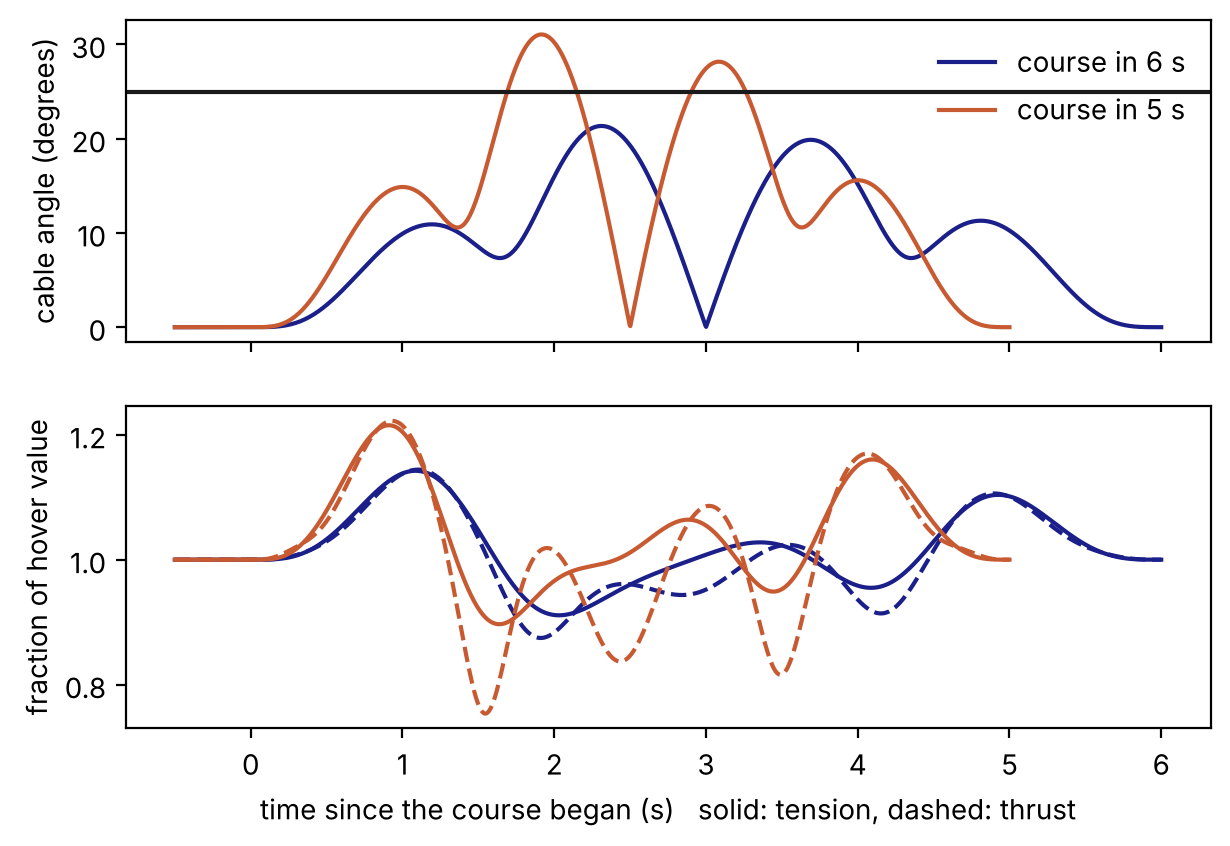

In [5]:
plan = Plan()
hurry = Plan(travel=T_HURRY)
fig, axes = plt.subplots(2, 1, figsize=(7, 4.6), sharex=True)
for pl, col in ((plan, INDIGO), (hurry, TERRACOTTA)):
    r = plan_report(pl)
    axes[0].plot(r["t"] - pl.start, r["swing"], color=col, label="course in %.0f s" % pl.travel)
    axes[1].plot(r["t"] - pl.start, r["T"] / (P0.m_L * P0.g), color=col)
    axes[1].plot(r["t"] - pl.start, r["f"] / ((P0.m_Q + P0.m_L) * P0.g), color=col, ls="--")
    print("%.0f s: cable up to %.1f deg, tension %.2f to %.2f N, thrust %.1f to %.1f N, torque up to %.3f N m"
          % (pl.travel, r["swing"].max(), r["T"].min(), r["T"].max(), r["f"].min(), r["f"].max(), r["tau"].max()))
axes[0].axhline(CONE_DEG, color=INK)
axes[0].set_ylabel("cable angle (degrees)")
axes[0].legend(frameon=False)
axes[1].set_ylabel("fraction of hover value")
axes[1].set_xlabel("time since the course began (s)   solid: tension, dashed: thrust")
plt.show()

## 4. Tracking a moving load

The cascade `eq6-load`, with the cable law `eq6-law-s2` and the attitude law `eq6-law` given the reference's
$\omega_d$, $\dot\omega_d$, $\Omega_d$, $\dot\Omega_d$ from the flat map. The closed loop below also contains the
blocks of the later sections, switched by `Options`. They are defined first and explained as they are used.

In [6]:
# ---- copied from verify/ch18.py: control
def gust(t, peak=2.0, t_on=GUST[0], t_off=GUST[1], direction=(0.25, -1.0, 0.0)):
    """The external force F_e on the quadrotor: a crosswind, a smooth pulse of `peak` newtons."""
    if not t_on < t < t_off:
        return np.zeros(3)
    return peak * np.sin(np.pi * (t - t_on) / (t_off - t_on)) ** 2 * unit(direction)


def no_gust(t):
    return np.zeros(3)


def cascade_thrust(state, ref, k, p=P0, feedforward=True):
    """The thrust vector the load cascade asks for (eq6-load), for a moving
    reference `ref` (a dict from Plan.flat). With feedforward=True the cable
    law eq6-law-s2 uses the reference's omega_d and its rate from the flat map.
    Returns F and the cable direction q_d that the position loop asks for."""
    q, omega = state.q, state.omega
    m = p.m_Q + p.m_L
    F_L = -k.k_x * (state.x_L - ref["x_L"]) - k.k_v * (state.v_L - ref["v_L"]) + m * (ref["a_L"] + p.g * E3)
    A = F_L + p.m_Q * p.l * (omega @ omega) * q
    qd = -unit(A)
    omegad, omegad_dot = (ref["omega"], ref["omega_dot"]) if feedforward else (np.zeros(3), np.zeros(3))
    omega_dot = (tangent(q, omegad_dot) - (q @ omegad) * cross(omega, q)
                 - k.k_q * e_q(q, qd) - k.k_omega * e_omega(q, omega, omegad))      # eq6-law-s2
    return (A @ q) * q + p.m_Q * p.l * cross(q, omega_dot), qd


def attitude_stage(state, F, ref, k, p=P0, feedforward=True):
    """eq6-Rd and eq6-law: thrust along the body axis and the torque that turns it."""
    Rd = desired_attitude(F, E1)
    Omegad, Omegad_dot = (ref["Omega"], ref["Omega_dot"]) if feedforward else (np.zeros(3), np.zeros(3))
    tau = attitude_tracking_torque(state.R, state.Omega, Rd, Omegad, Omegad_dot, p.J, k.k_R, k.k_Omega)
    return F @ (state.R @ E3), tau


def bare_quadrotor_thrust(state, ref, k, p=P0):
    """A controller that does not know about the cable: eq6-Fd for the quadrotor,
    sent one cable length above the load's reference, carrying the believed
    total weight. The swing of the load is a disturbance to it."""
    m = p.m_Q + p.m_L
    x_Q = state.x_L - p.l * state.q
    v_Q = state.v_L - p.l * cross(state.omega, state.q)
    return -k.k_x * (x_Q - (ref["x_L"] + p.l * E3)) - k.k_v * (v_Q - ref["v_L"]) + m * (ref["a_L"] + p.g * E3)


# ---- copied from verify/ch08.py: a small quadratic program, and the projection eq8-proj
def solve_qp(Q, c, A, b, tol=1e-9):
    """min 0.5 z'Qz + c'z  subject to  A z <= b, for a handful of constraints.

    Tries every active set, smallest first, and returns the first KKT point.
    Returns None when the constraints cannot all be met.
    """
    from itertools import combinations
    n, m = len(c), len(b)
    for size in range(m + 1):
        for act in combinations(range(m), size):
            act = list(act)
            if act:
                Aa = A[act]
                K = np.block([[Q, Aa.T], [Aa, np.zeros((size, size))]])
                try:
                    sol = np.linalg.solve(K, np.concatenate([-c, b[act]]))
                except np.linalg.LinAlgError:
                    continue
                z, lam = sol[:n], sol[n:]
            else:
                z, lam = np.linalg.solve(Q, -c), np.zeros(0)
            if np.all(A @ z <= b + tol * (1 + np.abs(b))) and np.all(lam >= -tol):
                return z
    return None


def proj(theta, y, bound, eps=0.1):
    """Smooth projection of Lavretsky and Gibson: acts for |theta| > bound / sqrt(1 + eps), keeps |theta| <= bound."""
    f = ((1 + eps) * theta @ theta - bound**2) / (eps * bound**2)
    grad = 2 * (1 + eps) * theta / (eps * bound**2)
    if f > 0 and y @ grad > 0:
        return y - grad * (grad @ y) / (grad @ grad) * f
    return y


# ---- copied from verify/ch18.py: safety, adaptation
def cone_terms(q, omega, p=P0, q_c=Q_C, theta_max=np.radians(CONE_DEG)):
    """H, H_dot and (a, b) with H_ddot = a + b . F for the thrust vector F.
    This is eq8-cone-ddot for the cable: mass m_Q, and F - m g e3 replaced by -F."""
    H = q @ q_c - np.cos(theta_max)
    H_dot = omega @ cross(q, q_c)
    tang = q_c - (q @ q_c) * q
    return H, H_dot, -(omega @ omega) * (q @ q_c), -tang / (p.m_Q * p.l)


def safety_filter(state, F, p=P0, alpha=ALPHA, theta_max=np.radians(CONE_DEG), T_min=T_MIN,
                  Delta=None, cone=True, tension=True):
    """The thrust vector closest to F that satisfies the cone condition eq8-rd2 and
    keeps the tension of eq4-load-tension above T_min. Both are linear in F.
    Delta is an estimate of the lumped uncertainty, added to F in the model."""
    q, omega = state.q, state.omega
    Delta = np.zeros(3) if Delta is None else Delta
    rows, rhs = [], []
    if cone:
        Hc, Hd, a, b = cone_terms(q, omega, p, theta_max=theta_max)
        a1, a2 = alpha
        rows.append(-b)                                    # a + b.(F + Delta) + (a1+a2) Hd + a1 a2 H >= 0
        rhs.append(a + b @ Delta + (a1 + a2) * Hd + a1 * a2 * Hc)
    if tension:
        rows.append(q)                                     # q.(F + Delta) <= m_Q l |omega|^2 - (m/m_L) T_min
        rhs.append(p.m_Q * p.l * omega @ omega - (p.m_Q + p.m_L) / p.m_L * T_min - q @ Delta)
    if not rows:
        return F, False
    A, bb = np.array(rows), np.array(rhs)
    if np.all(A @ F <= bb):
        return F, False
    z = solve_qp(np.eye(3), -F, A, bb)
    return (F if z is None else z), True


def tension_floor(state, f, p=P0, T_min=T_MIN):
    """The smallest thrust for which eq4-load-tension gives at least T_min, at the
    attitude the vehicle has now. The thrust enters the tension directly."""
    c = -state.q @ (state.R @ E3)
    if c <= 1e-3:
        return f
    need = ((p.m_Q + p.m_L) / p.m_L * T_min - p.m_Q * p.l * state.omega @ state.omega) / c
    return max(f, need)


@dataclass
class AdaptGains:
    k_Delta: float = 2000.0       # adaptation gain
    k_f: float = 6.0              # cutoff, rad/s
    k_pred: float = 10.0          # gain on the prediction errors, 1/s
    Delta_max: float = 6.0        # radius of the projection ball, N


class Adaptation:
    """A state predictor for the load velocity and the cable angular velocity,
    an adaptation law with the projection of eq8-proj, and the low-pass filter
    eq8-filter. The lumped uncertainty Delta is a force in the world frame that
    adds to the thrust vector."""

    def __init__(self, state, gains=None, p=P0):
        self.k, self.p = gains or AdaptGains(), p
        self.v_p, self.omega_p = state.v_L.copy(), state.omega.copy()
        self.Deltahat, self.Delta_f = np.zeros(3), np.zeros(3)

    def errors(self, state):
        return self.v_p - state.v_L, self.omega_p - state.omega

    def direction(self, state):
        """y of the adaptation law: -(q q^T) v_tilde + l omega_tilde x q."""
        v_t, om_t = self.errors(state)
        return -(state.q @ v_t) * state.q + self.p.l * cross(om_t, state.q)

    def rates(self, state, F_applied):
        p, k, q = self.p, self.k, state.q
        m = p.m_Q + p.m_L
        v_t, om_t = self.errors(state)
        Fe = F_applied + self.Deltahat
        v_p_dot = (q @ Fe - p.m_Q * p.l * state.omega @ state.omega) * q / m - p.g * E3 - k.k_pred * v_t
        omega_p_dot = -cross(q, Fe) / (p.m_Q * p.l) - k.k_pred * om_t
        return v_p_dot, omega_p_dot

    def step(self, state, F_applied, h=H):
        k = self.k
        y = self.direction(state)
        v_p_dot, omega_p_dot = self.rates(state, F_applied)
        self.v_p = self.v_p + h * v_p_dot
        self.omega_p = self.omega_p + h * omega_p_dot
        self.Deltahat = self.Deltahat + h * k.k_Delta * proj(self.Deltahat, y, k.Delta_max)
        norm = np.linalg.norm(self.Deltahat)
        if norm > k.Delta_max:
            self.Deltahat *= k.Delta_max / norm
        self.Delta_f = self.Delta_f + (1.0 - np.exp(-k.k_f * h)) * (self.Deltahat - self.Delta_f)


def lumped_uncertainty(v_L_dot, d, p_true=P_TRUE, p=P0):
    """Delta = d - (m_L - m_L0)(v_L_dot + g e3): what must be added to the thrust
    vector in the believed model to reproduce the true motion."""
    return d - (p_true.m_L - p.m_L) * (v_L_dot + p.g * E3)

In [7]:
# ---- copied from verify/ch14.py: the map (+), the projector Pi_C, the constraint matrix C
def expm_series(M):
    """Matrix exponential to third order, for a small step."""
    M2 = M @ M
    return np.eye(M.shape[0]) + M + M2 / 2 + M2 @ M / 6


def s2_C(q, om):
    """Constraint matrix: the linear state s = (xi, delta omega) satisfies C s = 0."""
    C = np.zeros((2, 6))
    C[0, :3] = q
    C[1, :3] = np.cross(q, om)
    C[1, 3:] = q
    return C


def s2_Pi(q, om):
    """Projector onto ker C that keeps xi's tangent part and delta omega's tangent part."""
    Pq = np.eye(3) - np.outer(q, q)
    E = np.zeros((6, 6))
    E[:3, :3] = Pq
    E[3:, 3:] = Pq
    E[3:, :3] = -np.outer(q, np.cross(q, om))
    return E


def s2_oplus(q, om, s):
    """(q, om) (+) s: turn by exp(xi^) and carry the velocity along."""
    Pq = np.eye(3) - np.outer(q, q)
    Rs = expm_so3(Pq @ s[:3])
    return Rs @ q, Rs @ (om + Pq @ s[3:])


def s2_ominus(q2, om2, q1, om1):
    """The variation s with (q1, om1) (+) s = (q2, om2)."""
    ax = np.cross(q1, q2)
    na = np.linalg.norm(ax)
    xi = np.zeros(3) if na < 1e-14 else np.arctan2(na, q1 @ q2) * ax / na
    Rs = expm_so3(xi)
    dom_t = Rs.T @ om2 - om1
    return np.concatenate([xi, dom_t - (om1 @ np.cross(xi, q1)) * q1])


def pendulum_linearize(qd, omegad, Fd, m, l, g):
    """thm7-s2, copied from case_studies/robots/spherical_pendulum.py: A, B and C."""
    A = np.zeros((6, 6))
    A[:3, :3] = hat(omegad)
    A[:3, 3:] = I3 - np.outer(qd, qd)
    A[3:, :3] = hat(Fd - m * g * E3) @ hat(qd) / (m * l)
    B = np.vstack([np.zeros((3, 3)), hat(qd) / (m * l)])
    C = np.block([[qd, np.zeros(3)], [cross(qd, omegad), qd]])
    return A, B, C


def body_linearize(Rd, Omegad, J):
    """thm7-so3 with rho = 0, copied from case_studies/robots/rigid_body.py: A and B."""
    Ji = np.linalg.inv(J)
    A = np.zeros((6, 6))
    A[:3, :3] = -hat(Omegad)
    A[:3, 3:] = I3
    A[3:, 3:] = Ji @ (hat(J @ Omegad) - hat(Omegad) @ J)
    return A, np.vstack([np.zeros((3, 3)), Ji])


# ---- copied from verify/ch18.py: the filter for the cable, the linear state, the closed loop
def cable_rhs(q, omega, F, p=P0):
    """q_dot and omega_dot of the cable under the thrust vector F (second line of eq4-load)."""
    return cross(omega, q), -cross(q, F) / (p.m_Q * p.l)


def cable_step(q, omega, F, h, p=P0):
    """One fourth-order step of the cable with F held, then back onto the sphere."""
    def f(z):
        a, b = cable_rhs(z[:3], z[3:], F, p)
        return np.concatenate([a, b])
    z = np.concatenate([q, omega])
    k1 = f(z)
    k2 = f(z + h / 2 * k1)
    k3 = f(z + h / 2 * k2)
    k4 = f(z + h * k3)
    z = z + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    q = unit(z[:3])
    return q, tangent(q, z[3:])


def cable_A(q, omega, F, p=P0):
    """A of eq7-s2-lin for the cable: the library's pendulum block."""
    return pendulum_linearize(q, omega, p.m_Q * p.g * E3 - F, p.m_Q, p.l, p.g)[0]


@dataclass
class FilterNoise:
    sig_y: float = np.sqrt(1e-3)             # reading of l q, per coordinate, m (ex14-pendulum)
    q_xi: float = 1e-9                       # process noise per step, direction
    q_omega: float = 2e-5                    # process noise per step, angular velocity
    sig0_q: float = 0.3                      # initial standard deviation, rad
    sig0_omega: float = 0.5                  # rad/s
    every: int = 5                           # a reading every `every` steps: 100 Hz


class CableFilter:
    """def14-vekf with the cable equation in place of the free pendulum.
    The quadrotor's attitude and thrust are taken as known."""

    def __init__(self, qhat, omegahat, noise=None, p=P0):
        self.n, self.p = noise or FilterNoise(), p
        self.qhat, self.omegahat = unit(qhat), tangent(unit(qhat), omegahat)
        Pi = s2_Pi(self.qhat, self.omegahat)
        S0 = np.diag([self.n.sig0_q**2] * 3 + [self.n.sig0_omega**2] * 3)
        self.Sigma = Pi @ S0 @ Pi.T
        self.Sigma_n = np.diag([self.n.q_xi] * 3 + [self.n.q_omega] * 3)
        self.Sigma_y = np.eye(3) * self.n.sig_y**2

    def propagate(self, F, h=H):
        A_k = expm_series(cable_A(self.qhat, self.omegahat, F, self.p) * h)
        self.qhat, self.omegahat = cable_step(self.qhat, self.omegahat, F, h, self.p)
        Pi = s2_Pi(self.qhat, self.omegahat)
        self.Sigma = Pi @ (A_k @ self.Sigma @ A_k.T + self.Sigma_n) @ Pi.T

    def correct(self, y):
        l = self.p.l
        C_y = np.hstack([-l * hat(self.qhat), np.zeros((3, 3))])
        ytilde = l * self.qhat - y
        S = self.Sigma
        Ktilde = S @ C_y.T @ np.linalg.inv(C_y @ S @ C_y.T + self.Sigma_y)
        s = -Ktilde @ ytilde
        IK = np.eye(6) - Ktilde @ C_y
        S = IK @ S @ IK.T + Ktilde @ self.Sigma_y @ Ktilde.T
        turn = expm_so3(s[:3])
        self.qhat, self.omegahat = s2_oplus(self.qhat, self.omegahat, s)
        Tm = np.zeros((6, 6))
        Tm[:3, :3] = turn
        Tm[3:, 3:] = turn
        Pi = s2_Pi(self.qhat, self.omegahat)
        self.Sigma = Pi @ Tm @ S @ Tm.T @ Pi.T
        return s

    def nees(self, q, omega):
        err = s2_ominus(self.qhat, self.omegahat, q, omega)
        return float(err @ np.linalg.pinv(self.Sigma, rcond=1e-10) @ err) / 4


def linear_state(state, ref):
    """The linear state computed from a state and a reference state (tbl7-dictionary):
    (e_x, e_v, e_q, omega - omega_d, e_R, e_Omega + Omega_d x e_R)."""
    eR = e_R(state.R, ref.R)
    return np.concatenate([state.x_L - ref.x_L, state.v_L - ref.v_L, e_q(state.q, ref.q),
                           state.omega - ref.omega, eR,
                           e_Omega(state.R, state.Omega, ref.R, ref.Omega) + cross(ref.Omega, eR)])


@dataclass
class Options:
    controller: str = "cascade"      # "cascade", "lqr" or "bare"
    feedforward: bool = True         # the flat feedforward: omega_d, Omega_d and their rates
    feedforward_attitude: bool | None = None   # None: the same as `feedforward`
    adapt: bool = True
    safe: bool = True                # cone and tension filter
    estimate: bool = True            # run the filter on the readings of the cable
    use_estimate: bool = True        # and let the controller see its estimate, not the truth
    gust: bool = True
    m_L: float = M_L_TRUE
    cone_deg: float = CONE_DEG
    t_end: float = T_END
    seed: int = 18
    saturate: bool = True
    qhat0: np.ndarray | None = None  # initial estimate of the cable direction
    state0: object = None            # initial state (default: the plan's)
    gust_fn: object = None
    adapt_gains: AdaptGains | None = None
    noise: FilterNoise | None = None
    barrier_uses_estimate: bool = True
    filter_uses_estimate: bool = True


def run(plan, opt=None, gains=None, lqr=None):
    """Fly the plan. Returns a dict of logged arrays, one row per step."""
    opt, k = opt or Options(), gains or Gains()
    rng = np.random.default_rng(opt.seed)
    plant = Robot(replace(P0, m_L=opt.m_L))
    pt = plant.params
    n = int(round(opt.t_end / H))
    state = opt.state0 if opt.state0 is not None else plan.state(0.0)
    theta_max = np.radians(opt.cone_deg)
    wind = (opt.gust_fn or gust) if opt.gust else no_gust
    noise = opt.noise or FilterNoise()
    filt = CableFilter(opt.qhat0 if opt.qhat0 is not None else state.q, np.zeros(3), noise)
    adapt = Adaptation(state, opt.adapt_gains)
    log = {key: [] for key in ("t", "x_L", "x_d", "q", "q_d", "qhat", "omega", "omegahat", "R", "x_Q", "f",
                               "tau", "T", "H", "H1", "Deltahat", "Delta_f", "Delta", "d", "active", "manifold",
                               "nees", "v_tilde", "omega_tilde", "e_x", "swing", "F_cmd", "F_safe", "sat",
                               "T_ref", "q_ref", "e_qhat", "e_omegahat", "Sigma_q", "v_L", "Omega", "filter_res", "y_err")}
    for i in range(n + 1):
        t = i * H
        ref = plan.flat(t)
        # --- the reading of the cable, and the state the controller sees
        y_err = np.nan
        if opt.estimate and i % noise.every == 0:
            y = P0.l * state.q + noise.sig_y * rng.normal(size=3)
            y_err = np.degrees(np.arccos(np.clip(unit(y) @ state.q, -1, 1)))
            qhat_before = filt.qhat
            filt.correct(y)
            if i == 0:
                first_error = np.degrees(np.arccos(np.clip(qhat_before @ state.q, -1, 1)))
        if opt.estimate and opt.use_estimate:
            x_Q = state.x_L - pt.l * state.q                      # the quadrotor's own state: known
            v_Q = state.v_L - pt.l * cross(state.omega, state.q)
            seen = State(x_L=x_Q + P0.l * filt.qhat, v_L=v_Q + P0.l * cross(filt.omegahat, filt.qhat),
                            q=filt.qhat, omega=filt.omegahat, R=state.R, Omega=state.Omega)
        else:
            seen = state
        # --- the controller
        active = False
        if opt.controller == "lqr":
            s = linear_state(seen, plan.state(t))
            du = -lqr[min(i, len(lqr) - 1)] @ s
            f, tau = ref["f"] + du[0], ref["tau"] + du[1:]
            F = f * seen.R @ E3
            qd = ref["q"]
        else:
            if opt.controller == "bare":
                F, qd = bare_quadrotor_thrust(seen, ref, k), ref["q"]
            else:
                F, qd = cascade_thrust(seen, ref, k, feedforward=opt.feedforward)
            if opt.adapt:
                F = F - adapt.Delta_f
            F_cmd = F
            if opt.safe:
                F, active = safety_filter(seen, F, theta_max=theta_max,
                                          Delta=adapt.Delta_f if (opt.adapt and opt.barrier_uses_estimate)
                                          else None)
            ff_att = opt.feedforward if opt.feedforward_attitude is None else opt.feedforward_attitude
            f, tau = attitude_stage(seen, F, ref, k, feedforward=ff_att)
            if opt.safe:
                f = tension_floor(seen, f)
        if opt.controller == "lqr":
            F_cmd = F
        sat = False
        if opt.saturate:
            f2, tau2 = float(np.clip(f, 0.0, F_MAX)), np.clip(tau, -TAU_MAX, TAU_MAX)
            sat = (f2 != f) or bool(np.any(tau2 != tau))
            f, tau = f2, tau2
        d = wind(t)
        u = (f, tau, d)
        # --- log
        acc = plant.dynamics(state, u)
        Hc, Hd, _, _ = cone_terms(state.q, state.omega, theta_max=theta_max)
        v_t, om_t = adapt.errors(seen)
        row = dict(t=t, x_L=state.x_L, x_d=ref["x_L"], q=state.q, q_d=qd, qhat=filt.qhat, omega=state.omega,
                   omegahat=filt.omegahat, R=state.R, x_Q=state.x_L - pt.l * state.q, f=f, tau=tau,
                   T=plant.tension(state, u), H=Hc, H1=Hd + ALPHA[0] * Hc, Deltahat=adapt.Deltahat.copy(),
                   Delta_f=adapt.Delta_f.copy(), Delta=lumped_uncertainty(acc[0], d, pt), d=d, active=active,
                   manifold=plant.on_manifold(state), nees=(filt.nees(state.q, state.omega) if (opt.estimate and i % noise.every == 0)
                                                           else np.nan),
                   v_tilde=np.linalg.norm(v_t), omega_tilde=np.linalg.norm(om_t),
                   e_x=np.linalg.norm(state.x_L - ref["x_L"]),
                   swing=np.degrees(np.arccos(np.clip(state.q @ Q_C, -1, 1))), F_cmd=F_cmd, F_safe=F, sat=sat,
                   T_ref=ref["T"], q_ref=ref["q"],
                   e_qhat=np.degrees(np.arccos(np.clip(filt.qhat @ state.q, -1, 1))),
                   e_omegahat=np.linalg.norm(filt.omegahat - state.omega),
                   Sigma_q=np.sqrt(max(np.trace(filt.Sigma[:3, :3]), 0.0)), v_L=state.v_L, Omega=state.Omega,
                   y_err=y_err, filter_res=max(abs(np.linalg.norm(filt.qhat) - 1.0), abs(filt.qhat @ filt.omegahat),
                                  np.abs(s2_C(filt.qhat, filt.omegahat) @ filt.Sigma).max()))
        for key, val in row.items():
            log[key].append(val)
        if i == n or not np.all(np.isfinite(state.x_L)) or np.linalg.norm(state.x_L - ref["x_L"]) > 20.0:
            break
        # --- adaptation and filter see the thrust that was applied
        F_applied = f * state.R @ E3
        if opt.adapt:
            adapt.step(seen, F_applied)
        if opt.estimate:
            filt.propagate(F_applied + (adapt.Delta_f if (opt.adapt and opt.filter_uses_estimate) else 0.0))
        state = plant.step(state, u, H)
    out = {key: np.array(val) for key, val in log.items()}
    out["final"] = state
    out["first_error"] = first_error if opt.estimate else np.nan
    out["completed"] = len(out["t"]) == n + 1
    return out


def wall_clearance(o):
    """Smallest height of the load above the top of the wall while it is over it, m."""
    x = o["x_L"]
    near = np.abs(x[:, 0] - WALL["x"]) < 0.15
    return float((x[near, 2] - WALL["height"]).min()) if near.any() else float("nan")


def settle_time(o, tol=0.05):
    """Time after which the load stays within `tol` of its reference."""
    late = o["e_x"] > tol
    if not late.any():
        return 0.0
    return float(o["t"][min(len(late) - 1, len(late) - int(np.argmax(late[::-1])))])


def summarize(o, plan):
    """The numbers of the mission report and of the ablation table."""
    t = o["t"]
    t_set = plan.start + plan.travel
    travel = (t >= plan.start) & (t <= t_set)
    after = t >= t_set
    i_set = int(np.argmin(np.abs(t - t_set)))
    seen = t >= 1.0
    return dict(
        completed=bool(o["completed"]),
        err_rms_cm=float(100 * np.sqrt(np.mean(o["e_x"][travel] ** 2))) if travel.any() else float("nan"),
        err_max_cm=float(100 * o["e_x"].max()),
        err_setdown_cm=float(100 * o["e_x"][min(i_set, len(t) - 1)]),
        err_final_cm=float(100 * o["e_x"][-1]),
        swing_setdown_deg=float(o["swing"][min(i_set, len(t) - 1)]),
        swing_after_deg=float(o["swing"][after].max()) if after.any() else float("nan"),
        speed_setdown=float(np.linalg.norm(o["v_L"][min(i_set, len(t) - 1)])),
        swing_max_deg=float(o["swing"].max()),
        clearance_cm=100 * wall_clearance(o),
        T_min=float(o["T"].min()), H_min=float(o["H"].min()),
        f_max=float(o["f"].max()), f_min=float(o["f"].min()), tau_max=float(np.abs(o["tau"]).max()),
        est_rms_deg=float(np.sqrt(np.mean(o["e_qhat"][seen] ** 2))),
        est_omega_rms=float(np.sqrt(np.mean(o["e_omegahat"][seen] ** 2))),
        nees=float(np.nanmean(o["nees"][seen])) if np.isfinite(o["nees"][seen]).any() else float("nan"),
        active_frac=float(np.mean(o["active"])), saturated_frac=float(np.mean(o["sat"])),
        manifold=float(o["manifold"].max()), filter_res=float(o["filter_res"].max()))

flat feedforward             error   0.0 cm RMS,   0.0 cm worst | at set-down   0.0 cm, cable  0.0 deg | swing 21.4 deg | H >=  0.025 | T >= 2.68 N
feedforward set to zero      error  47.7 cm RMS,  87.2 cm worst | at set-down  55.4 cm, cable 22.5 deg | swing 47.7 deg | H >= -0.233 | T >= 2.76 N


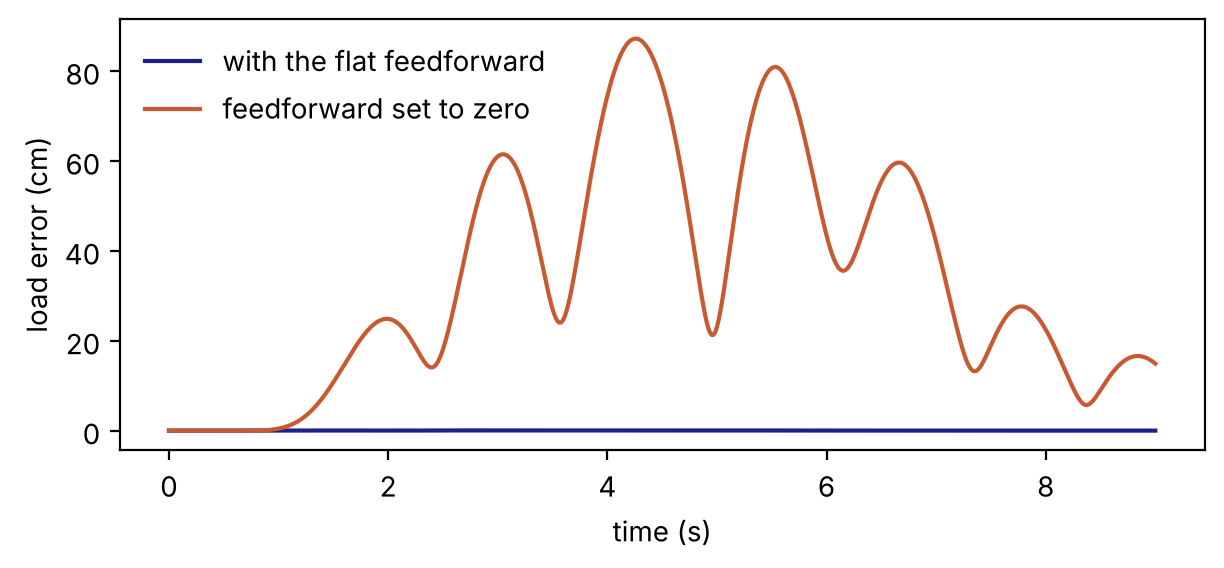

In [8]:
def show(name, o, pl=None):
    s = summarize(o, pl or plan)
    print("%-28s error %5.1f cm RMS, %5.1f cm worst | at set-down %5.1f cm, cable %4.1f deg | swing %4.1f deg"
          " | H >= %6.3f | T >= %4.2f N" % (name, s["err_rms_cm"], s["err_max_cm"], s["err_setdown_cm"],
                                             s["swing_setdown_deg"], s["swing_max_deg"], s["H_min"], s["T_min"]))
    return s


ideal = dict(adapt=False, safe=False, estimate=False, gust=False, m_L=P0.m_L)   # the model as believed
nominal = run(plan, Options(**ideal))
no_ff = run(plan, Options(feedforward=False, **ideal))
show("flat feedforward", nominal)
show("feedforward set to zero", no_ff)
plt.figure(figsize=(7, 2.8))
plt.plot(nominal["t"], 100 * nominal["e_x"], color=INDIGO, label="with the flat feedforward")
plt.plot(no_ff["t"], 100 * no_ff["e_x"], color=TERRACOTTA, label="feedforward set to zero")
plt.xlabel("time (s)")
plt.ylabel("load error (cm)")
plt.legend(frameon=False)
plt.show()

## 5. Linearizing on the whole manifold

The linear state is $s = (\delta x_L, \delta v_L, \xi, \delta\omega, \eta, \delta\Omega)$ with the two constraints of
`eq7-s2-constraint` on its cable part. The cable block is the pendulum block of Chapter 7 for a bob of mass $m_Q$
pushed by $m_Q g\,e_3 - f R e_3$, the attitude block is the rigid body's, and the variation of the thrust vector
joins them.

In [9]:
# ---- copied from verify/ch18.py
def linearize(state, u, p=P0):
    """Variation-based linearization of eq4-load along a solution.

    Linear state s = (delta x_L, delta v_L, xi, delta omega, eta, delta Omega),
    input (delta f, delta tau). Returns A (18 x 18), B (18 x 4) and the
    constraint matrix C (2 x 18) with C s = 0.

    The cable block is thm7-s2 for a pendulum of mass m_Q pushed by the force
    m_Q g e3 - f R e3 (the cable equation m_Q l omega_dot = -q x f R e3 is
    eq7-pendulum with that force). The attitude block is thm7-so3 with rho = 0.
    Both are taken from the robot model library. The coupling is the variation
    of the thrust vector, delta(f R e3) = R e3 delta f - f R hat(e3) eta.
    """
    f, q, omega, R, Omega = u[0], state.q, state.omega, state.R, state.Omega
    m, b3 = p.m_Q + p.m_L, R @ E3
    F = f * b3
    A_c, B_c, C_c = pendulum_linearize(q, omega, p.m_Q * p.g * E3 - F, p.m_Q, p.l, p.g)
    A_a, B_a = body_linearize(R, Omega, p.J)
    dF_eta, dF_f = -f * R @ hat(E3), b3                    # delta F = dF_eta eta + dF_f delta f
    c = q @ F - p.m_Q * p.l * omega @ omega
    A, B = np.zeros((18, 18)), np.zeros((18, 4))
    A[0:3, 3:6] = I3
    # load: (m_Q + m_L)(v_L_dot + g e3) = (q . F - m_Q l |omega|^2) q
    A[3:6, 6:9] = (np.outer(q, cross(q, F)) - c * hat(q)) / m
    A[3:6, 9:12] = -2 * p.m_Q * p.l * np.outer(q, omega) / m
    A[3:6, 12:15] = np.outer(q, q) @ dF_eta / m
    B[3:6, 0] = np.outer(q, q) @ dF_f / m
    # cable: the pendulum block, driven by -delta F
    A[6:12, 6:12] = A_c
    A[6:12, 12:15] = -B_c @ dF_eta
    B[6:12, 0] = -B_c @ dF_f
    # attitude
    A[12:18, 12:18] = A_a
    B[12:18, 1:4] = B_a
    C = np.zeros((2, 18))
    C[:, 6:12] = C_c
    return A, B, C


def reachable_dimension(A, B, tol=1e-9):
    """Dimension of span [B, A B, A^2 B, ...], built one orthonormal direction at a time
    (the powers of A themselves are too badly scaled for a rank computation)."""
    basis = np.zeros((A.shape[0], 0))
    block = B
    for _ in range(A.shape[0]):
        new = []
        for col in block.T:
            col = col / max(np.linalg.norm(col), 1e-300)
            for _ in range(2):
                col = col - basis @ (basis.T @ col)
            if np.linalg.norm(col) > tol:
                col = col / np.linalg.norm(col)
                basis = np.column_stack([basis, col])
                new.append(col)
        if not new:
            break
        block = A @ np.column_stack(new)
    return basis.shape[1]


def null_basis(C):
    """Orthonormal basis Z of the constraint subspace ker C."""
    _, _, Vt = np.linalg.svd(C)
    return Vt[C.shape[0]:].T


def riccati(plan, Q, R_u, P_f, t0, t1, n_grid=None, p=P0):
    """Integrate eq7-riccati backwards along the plan with the classical fourth-order
    Runge-Kutta method on the sampling grid. Returns the times and the gains K(t)."""
    n = int(round((t1 - t0) / H)) if n_grid is None else n_grid
    hh = (t1 - t0) / n
    Ri = np.linalg.inv(R_u)

    def AB(t):
        o = plan.flat(t)
        A, B, _ = linearize(plan.state(t), (o["f"], o["tau"]), p)
        return A, B

    def rhs(P, A, B):
        return A.T @ P + P @ A - P @ B @ Ri @ B.T @ P + Q

    ts = t0 + hh * np.arange(n + 1)
    P = P_f.copy()
    Ks = np.zeros((n + 1, 4, 18))
    A1, B1 = AB(ts[n])
    Ks[n] = Ri @ B1.T @ P
    for k in range(n, 0, -1):
        Am, Bm = AB(ts[k] - hh / 2)
        A0, B0 = AB(ts[k - 1])
        k1 = rhs(P, A1, B1)
        k2 = rhs(P + hh / 2 * k1, Am, Bm)
        k3 = rhs(P + hh / 2 * k2, Am, Bm)
        k4 = rhs(P + hh * k3, A0, B0)
        P = P + hh / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        P = 0.5 * (P + P.T)
        A1, B1 = A0, B0
        Ks[k - 1] = Ri @ B1.T @ P
    return ts, Ks, P


Q_LQR = np.diag([40.0] * 3 + [8.0] * 3 + [20.0] * 3 + [2.0] * 3 + [10.0] * 3 + [0.2] * 3)


R_LQR = np.diag([0.5, 30.0, 30.0, 30.0])


def swing_start(state, deg, axis=E1):
    """The same state with the cable turned by `deg` about `axis`, and the load moved."""
    return State(x_L=state.x_L + np.array([0.3, -0.2, 0.1]), v_L=state.v_L,
                    q=expm_so3(np.radians(deg) * axis) @ state.q, omega=state.omega, R=state.R,
                    Omega=state.Omega)

hover: span [B, AB, ...] has dimension 16 of 18; on the constraint subspace 16 of 16


Riccati equation along the plan: 4 s


within 5 cm after: LQR 2.0 s, cascade 4.2 s


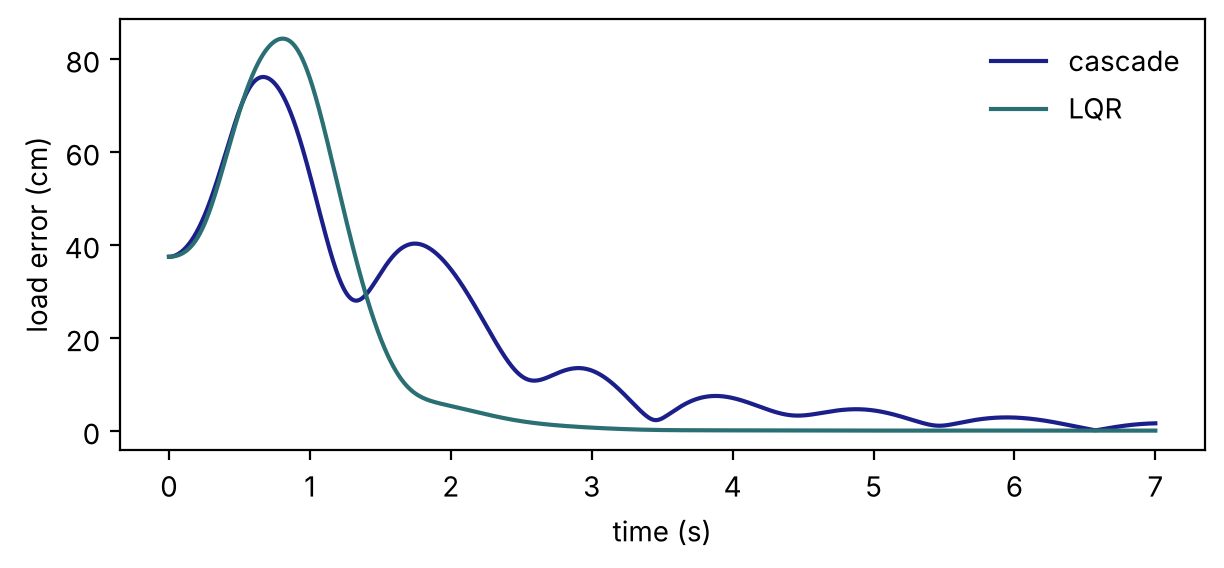

In [10]:
A0, B0, C0 = linearize(State(), RB.hover_input())
Z0 = null_basis(C0)
print("hover: span [B, AB, ...] has dimension %d of 18; on the constraint subspace %d of 16"
      % (reachable_dimension(A0, B0), reachable_dimension(Z0.T @ A0 @ Z0, Z0.T @ B0)))
t0 = time.time()
_, K_lqr, _ = riccati(plan, Q_LQR, R_LQR, Q_LQR, 0.0, T_END)
print("Riccati equation along the plan: %.0f s" % (time.time() - t0))
start = swing_start(plan.state(0.0), 30)        # the load 37 cm off, the cable swung by 30 degrees
lqr_run = run(plan, Options(controller="lqr", state0=start, t_end=7.0, **ideal), lqr=K_lqr)
cas_run = run(plan, Options(state0=start, t_end=7.0, **ideal))
print("within 5 cm after: LQR %.1f s, cascade %.1f s" % (settle_time(lqr_run), settle_time(cas_run)))
plt.figure(figsize=(7, 2.8))
plt.plot(cas_run["t"], 100 * cas_run["e_x"], color=INDIGO, label="cascade")
plt.plot(lqr_run["t"], 100 * lqr_run["e_x"], color=TEAL, label="LQR")
plt.xlabel("time (s)")
plt.ylabel("load error (cm)")
plt.legend(frameon=False)
plt.show()

## 6. What you did not pick up

The lumped uncertainty is a force that adds to the thrust vector,
$\Delta = F_e - (m_L - m_{L,0})(\ddot x_L + g\,e_3)$. Without adaptation the load hangs low by
$(m_L - m_{L,0})\,g/k_x$. The class `Adaptation` holds the predictor, the adaptation law with projection, and the
low-pass filter.

no adaptation                error  20.5 cm RMS,  25.4 cm worst | at set-down  21.8 cm, cable  2.7 deg | swing 18.8 deg | H >=  0.040 | T >= 4.01 N
adaptation                   error   3.0 cm RMS,   6.1 cm worst | at set-down   3.0 cm, cable  1.3 deg | swing 21.2 deg | H >=  0.026 | T >= 4.00 N
predicted sag 20.4 cm, final error without adaptation 20.6 cm


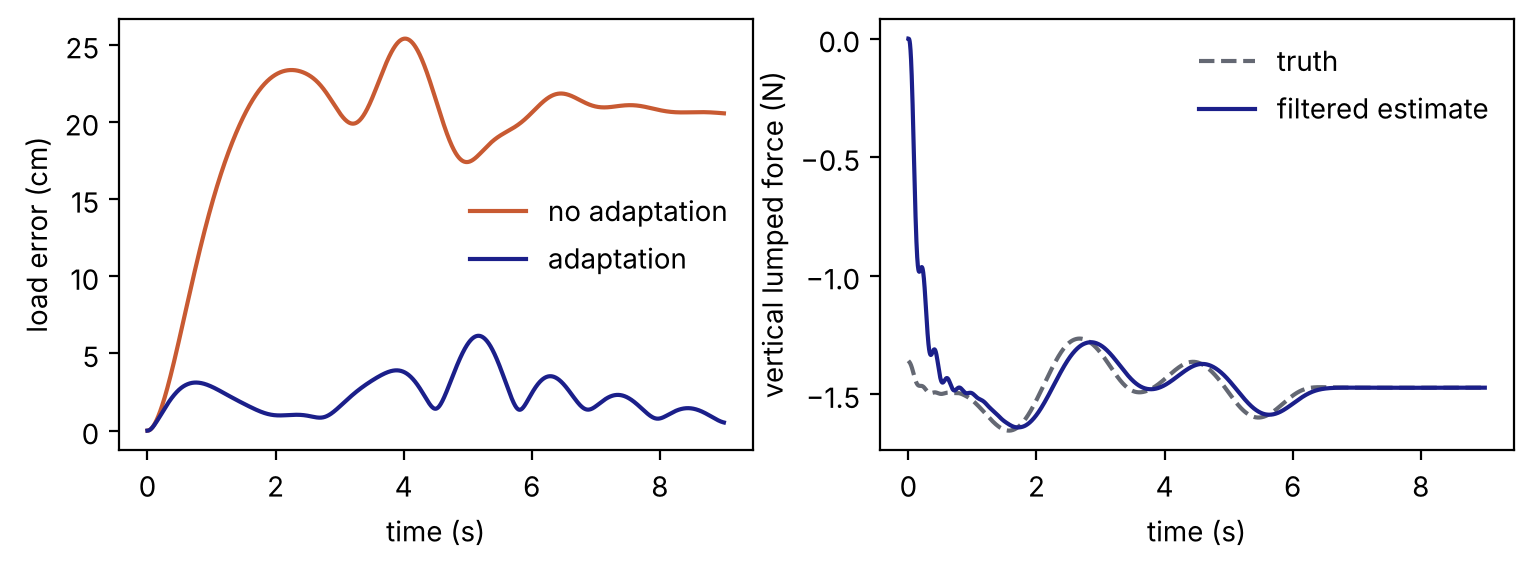

In [11]:
known = dict(use_estimate=False)                 # feed the controller the true state
plain = run(plan, Options(adapt=False, safe=False, **known))
adapted = run(plan, Options(safe=False, **known))
show("no adaptation", plain)
show("adaptation", adapted)
print("predicted sag %.1f cm, final error without adaptation %.1f cm"
      % (100 * (M_L_TRUE - P0.m_L) * P0.g / Gains().k_x, 100 * plain["e_x"][-1]))
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
axes[0].plot(plain["t"], 100 * plain["e_x"], color=TERRACOTTA, label="no adaptation")
axes[0].plot(adapted["t"], 100 * adapted["e_x"], color=INDIGO, label="adaptation")
axes[0].set_xlabel("time (s)")
axes[0].set_ylabel("load error (cm)")
axes[0].legend(frameon=False)
axes[1].plot(adapted["t"], adapted["Delta"][:, 2], color=MUTED, ls="--", label="truth")
axes[1].plot(adapted["t"], adapted["Delta_f"][:, 2], color=INDIGO, label="filtered estimate")
axes[1].set_xlabel("time (s)")
axes[1].set_ylabel("vertical lumped force (N)")
axes[1].legend(frameon=False)
plt.show()

## 7. Keeping the cable honest

The cone barrier $H = q\cdot q_c - \cos\theta_{\max}$ has relative degree two in the thrust vector, and the tension is
linear in it. `safety_filter` returns the thrust vector closest to the cascade's that satisfies both, and
`tension_floor` enforces the tension through the thrust itself. Fly the hurried plan with and without them.

hurried, no filter           error   2.7 cm RMS,   4.3 cm worst | at set-down   2.1 cm, cable  0.7 deg | swing 30.1 deg | H >= -0.041 | T >= 3.88 N
hurried, filter              error  23.0 cm RMS,  53.8 cm worst | at set-down  33.3 cm, cable 13.0 deg | swing 25.6 deg | H >= -0.004 | T >= 2.28 N


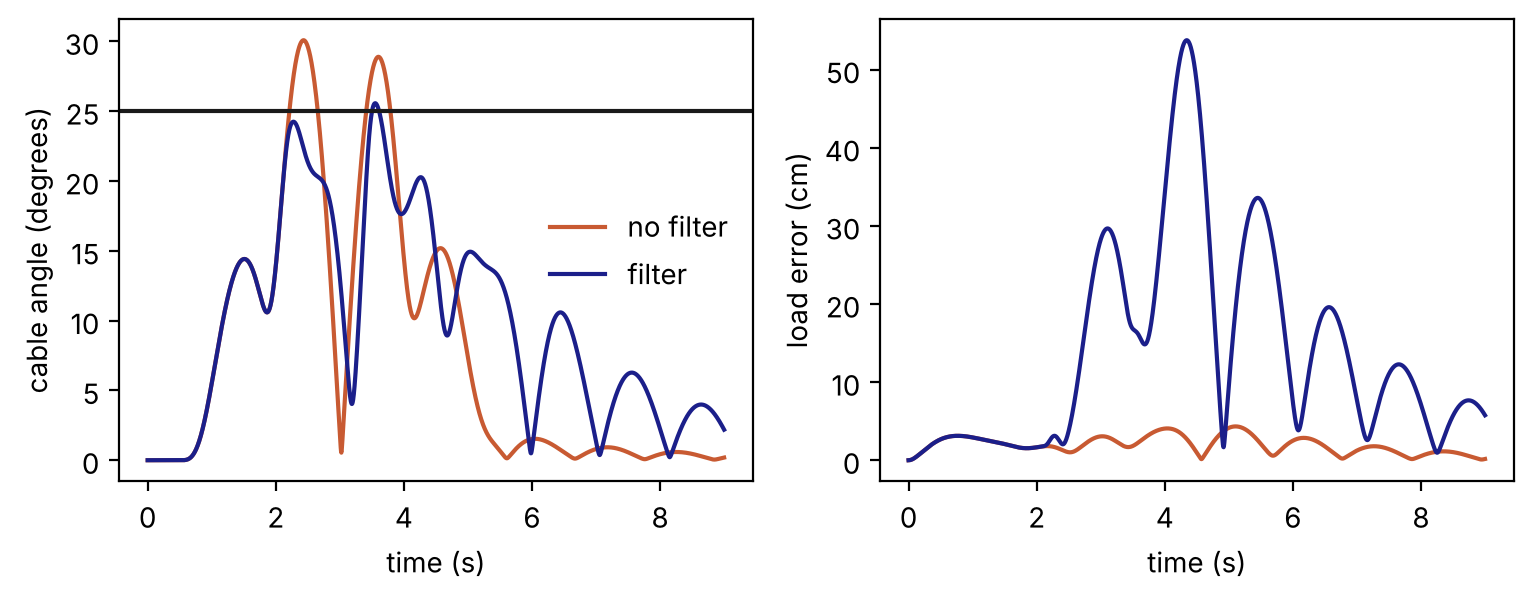

steep descent, no filter   smallest tension 0.00 N, smallest thrust 0.00 N, worst error 12 cm


steep descent, filter      smallest tension 0.79 N, smallest thrust 3.43 N, worst error 25 cm


In [12]:
free = run(hurry, Options(safe=False, gust=False, t_end=T_START + T_HURRY + 3.5, **known))
safe = run(hurry, Options(gust=False, t_end=T_START + T_HURRY + 3.5, **known))
show("hurried, no filter", free, hurry)
show("hurried, filter", safe, hurry)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.0))
axes[0].plot(free["t"], free["swing"], color=TERRACOTTA, label="no filter")
axes[0].plot(safe["t"], safe["swing"], color=INDIGO, label="filter")
axes[0].axhline(CONE_DEG, color=INK)
axes[0].set_xlabel("time (s)")
axes[0].set_ylabel("cable angle (degrees)")
axes[0].legend(frameon=False)
axes[1].plot(free["t"], 100 * free["e_x"], color=TERRACOTTA)
axes[1].plot(safe["t"], 100 * safe["e_x"], color=INDIGO)
axes[1].set_xlabel("time (s)")
axes[1].set_ylabel("load error (cm)")
plt.show()

drop = Plan(waypoints=DROP, travel=T_DROP)
for name, on in (("steep descent, no filter", False), ("steep descent, filter", True)):
    o = run(drop, Options(safe=on, gust=False, t_end=4.0, **known))
    print("%-26s smallest tension %.2f N, smallest thrust %.2f N, worst error %.0f cm"
          % (name, o["T"].min(), o["f"].min(), 100 * o["e_x"].max()))

## 8. Estimating the cable

`CableFilter` is the variation-based extended Kalman filter of Chapter 14 (`def14-vekf`) with the cable equation
as its model: the estimate stays on the sphere, the covariance in the constraint subspace. The reading is
$y = l\,q + n_y$, a hundred times a second. Start it 40° wrong.

after the first reading 4.1 deg; RMS after 1 s 0.56 deg; |qhat| - 1, qhat.omegahat, C Sigma below 3e-16


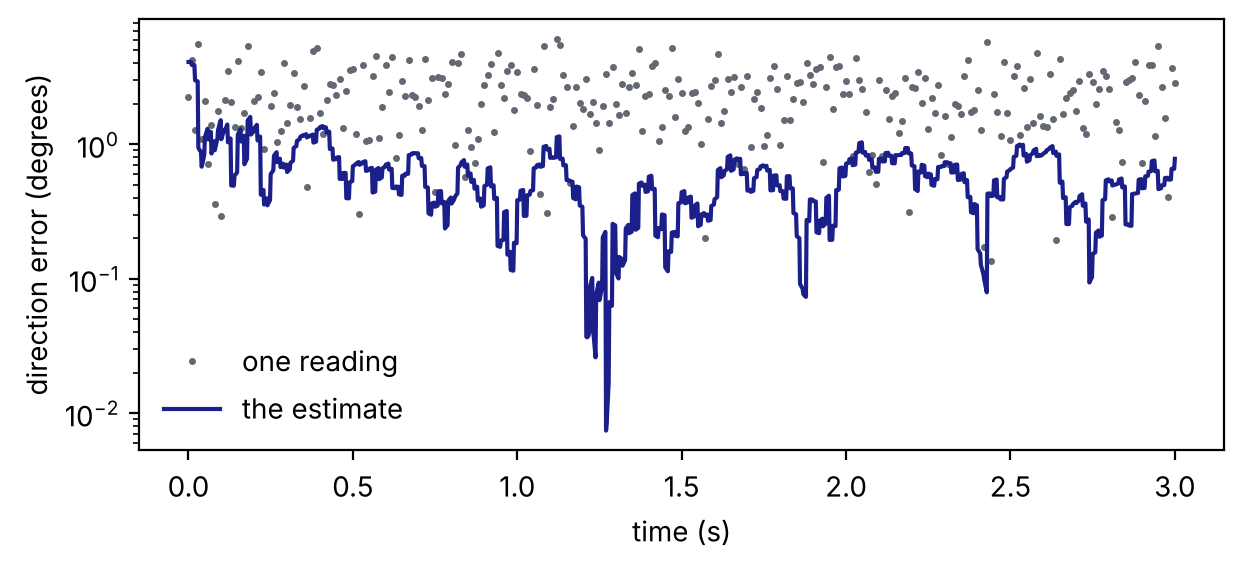

In [13]:
wrong = expm_so3(np.radians(40.0) * unit(np.array([1.0, 1.0, 0.0]))) @ -E3
est = run(plan, Options(t_end=3.0, qhat0=wrong, **known))
print("after the first reading %.1f deg; RMS after 1 s %.2f deg; |qhat| - 1, qhat.omegahat, C Sigma below %.0e"
      % (est["e_qhat"][0], np.sqrt(np.mean(est["e_qhat"][est["t"] > 1] ** 2)), est["filter_res"].max() + 1e-16))
ok = np.isfinite(est["y_err"])
plt.figure(figsize=(7, 2.8))
plt.semilogy(est["t"][ok], est["y_err"][ok], ".", color=MUTED, ms=3, label="one reading")
plt.semilogy(est["t"], est["e_qhat"], color=INDIGO, label="the estimate")
plt.xlabel("time (s)")
plt.ylabel("direction error (degrees)")
plt.legend(frameon=False)
plt.show()

## 9. The whole flight

Everything on, then one block removed at a time. Compare with the table of the chapter.

Everything on                error   3.9 cm RMS,   8.4 cm worst | at set-down   3.8 cm, cable  1.8 deg | swing 21.1 deg | H >=  0.027 | T >= 3.95 N


No flat feedforward          error  56.7 cm RMS, 116.6 cm worst | at set-down  40.3 cm, cable 17.1 deg | swing 31.4 deg | H >= -0.052 | T >= 0.79 N


No adaptation                error  20.4 cm RMS,  23.3 cm worst | at set-down  22.0 cm, cable  2.7 deg | swing 18.9 deg | H >=  0.040 | T >= 4.00 N


No cone and tension filter   error   3.9 cm RMS,   8.4 cm worst | at set-down   3.8 cm, cable  1.8 deg | swing 21.1 deg | H >=  0.027 | T >= 3.95 N


Truth in place of the estimate error   3.0 cm RMS,   6.1 cm worst | at set-down   3.0 cm, cable  1.3 deg | swing 21.2 deg | H >=  0.026 | T >= 4.00 N


Load treated as a disturbance error  43.5 cm RMS,  79.4 cm worst | at set-down  26.8 cm, cable 17.8 deg | swing 48.2 deg | H >= -0.240 | T >= 3.85 N
manifold residual over the flight 1.6e-14; thrust 16.6 to 21.9 N of 35.3; torque up to 0.33 N m of 1.0


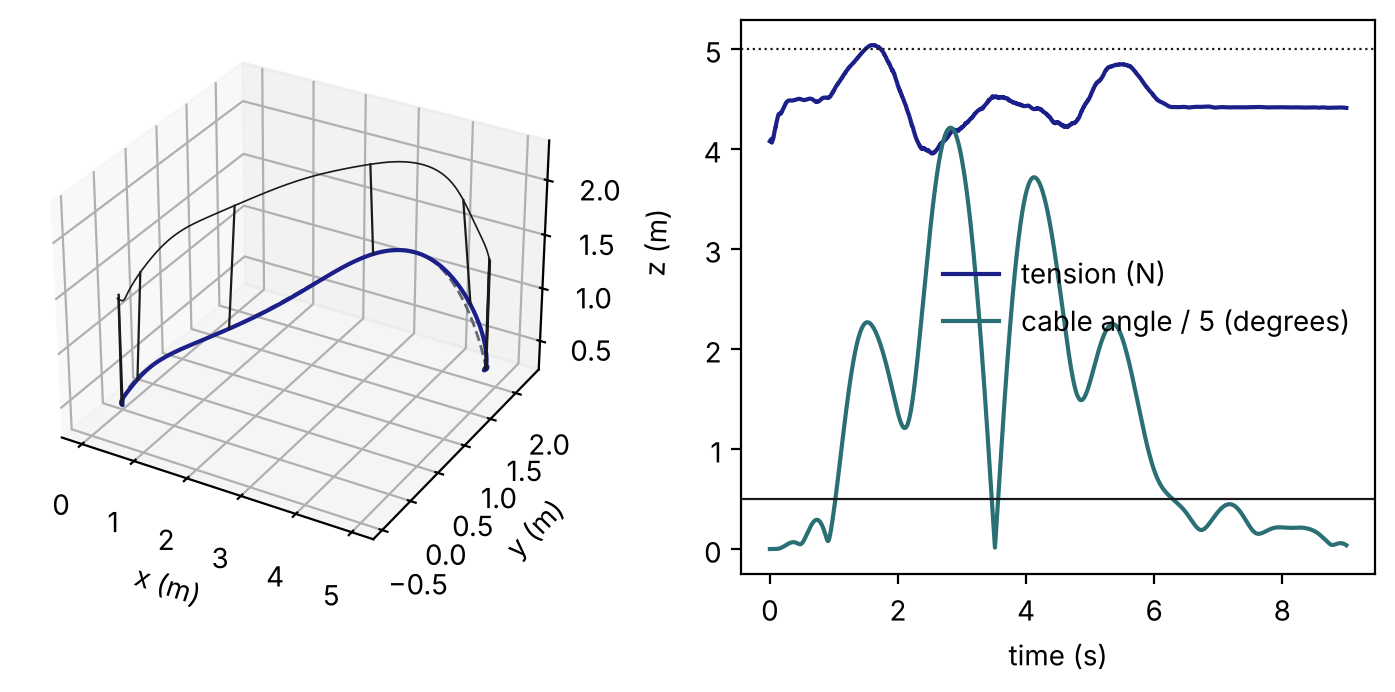

In [14]:
ablation = [("Everything on", Options()),
            ("No flat feedforward", Options(feedforward=False)),
            ("No adaptation", Options(adapt=False)),
            ("No cone and tension filter", Options(safe=False)),
            ("Truth in place of the estimate", Options(use_estimate=False)),
            ("Load treated as a disturbance", Options(controller="bare", adapt=False, safe=False))]
flights = {}
for name, opt in ablation:
    flights[name] = run(plan, opt)
    show(name, flights[name])
full = flights["Everything on"]
print("manifold residual over the flight %.1e; thrust %.1f to %.1f N of %.1f; torque up to %.2f N m of %.1f"
      % (full["manifold"].max(), full["f"].min(), full["f"].max(), F_MAX, np.abs(full["tau"]).max(), TAU_MAX))

fig = plt.figure(figsize=(9, 3.6))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot(*full["x_d"].T, color=MUTED, ls="--", lw=1)
ax.plot(*full["x_L"].T, color=INDIGO)
ax.plot(*full["x_Q"].T, color=INK, lw=0.6)
for k in range(0, len(full["t"]), 500):
    ax.plot(*np.array([full["x_Q"][k], full["x_L"][k]]).T, color=INK, lw=0.8)
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_zlabel("z (m)")
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(full["t"], full["T"], color=INDIGO, label="tension (N)")
ax2.plot(full["t"], full["swing"] / 5, color=TEAL, label="cable angle / 5 (degrees)")
ax2.axhline(T_MIN, color=INK, lw=0.8)
ax2.axhline(CONE_DEG / 5, color=INK, lw=0.8, ls=":")
ax2.set_xlabel("time (s)")
ax2.legend(frameon=False)
plt.show()

## Starting points for the exercises

- **A new course.** Edit `WAYPOINTS`, `TIME_FRACTIONS`, `WALL` and `T_TRAVEL` in section 1 and rerun, or build a
  plan directly: `Plan(waypoints=..., travel=..., times=...)`. `plan_report` gives swing, tension, thrust and torque.
- **Another load mass.** `run(plan, Options(m_L=0.6, adapt=False, use_estimate=False))`. The final height error
  should be $(m_L - m_{L,0})\,g/k_x$.
- **A lighter load and the tension floor.** `Options(m_L=0.1)` on the steep descent `drop`.
- **A tighter filter cone.** `Options(cone_deg=22.0)` sets the cone the filter enforces. The true limit stays
  `CONE_DEG`: read the true swing from `o["swing"]`. Triple the reading noise with
  `Options(noise=FilterNoise(sig_y=3 * FilterNoise().sig_y))`.
- **The LQR in the mission.** `run(plan, Options(controller="lqr", adapt=False, safe=False), lqr=K_lqr)`, and
  `swing_start(plan.state(0.0), deg)` for a bad start. `TAU_MAX` is the torque limit.
- **Wind on the load.** Add the terms of the exercise to `Robot.dynamics`.

In [15]:
# Exercise: load mass against sag, adaptation off
for m_L in (0.15, 0.3, 0.45, 0.6):
    o = run(plan, Options(m_L=m_L, adapt=False, safe=False, gust=False, use_estimate=False))
    print("m_L = %.2f kg: final height error %+.1f cm, predicted %+.1f cm"
          % (m_L, 100 * (o["x_L"][-1, 2] - o["x_d"][-1, 2]), -100 * (m_L - P0.m_L) * P0.g / Gains().k_x))

m_L = 0.15 kg: final height error +20.4 cm, predicted +20.4 cm


m_L = 0.30 kg: final height error -0.0 cm, predicted -0.0 cm


m_L = 0.45 kg: final height error -20.5 cm, predicted -20.4 cm


m_L = 0.60 kg: final height error -41.0 cm, predicted -40.9 cm
